In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from datetime import datetime
import openpyxl

In [2]:
#Configuración para la visualización 
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

In [3]:
#Cargo Tabla para modificarla 
data = pd.read_csv('marketing_campaign_data_messy.csv')
data.head(10)

,Campaign_ID,Campaign_Name,Start_Date,End_Date,Channel,Impressions,Clicks,Spend,Conversions,Active,Clicks,Campaign_Tag
0,CMP-00001,Q4_Summer_CMP-00001,24/11/2023 00:00,13/12/2023,TikTok,16795,197,$102.82,20.0,Y,NaN,TI
1,CMP-00002,Q1_Launch_CMP-00002,06/05/2023 00:00,12/05/2023,Facebook,1860,30,24.33,1.0,0,NaN,FA
2,CMP-00003,Q3_Winter_CMP-00003,13/12/2023 00:00,20/12/2023,Email,77820,843,1323.39,51.0,No,NaN,EM
3,CMP-00004,Q1_BlackFriday_CMP-00004,30/10/2023,03/11/2023,TikTok,55886,2019,2180.38,135.0,True,NaN,TI
4,CMP-00005,Q2_Winter_CMP-00005,22/04/2023 00:00,23/04/2023,Facebook,7265,169,252.44,30.0,Yes,NaN,FA
5,CMP-00006,Q4_BlackFriday_CMP-00006,15/10/2023 00:00,28/10/2023,Instagram,83386,2643,2697.03,NaN,1,NaN,IN
6,CMP-00007,Q3_Launch_CMP-00007,07/10/2023 00:00,23/10/2023,Facebook,38194,1135,1232.76,178.0,Yes,NaN,FA
7,CMP-00008,Q4_Launch_CMP-00008,23/05/2023,28/05/2023,Instagram,88498,1173,865.7,127.0,1,NaN,IN
8,CMP-00009,Q4_BlackFriday_CMP-00009,23/03/2023 00:00,01/04/2023,Google Ads,45131,1179,1046.18,104.0,1,NaN,GO
9,CMP-00010,Q2_Winter_CMP-00010,21/03/2023 00:00,01/04/2023,Email,61263,1153,1623.56,NaN,0,NaN,EM


In [4]:
#Revisar datos nulos 
print(data.isnull())

       Campaign_ID   Campaign_Name  Start_Date  End_Date  Channel  \
0             False          False       False     False    False   
1             False          False       False     False    False   
2             False          False       False     False    False   
3             False          False       False     False    False   
4             False          False       False     False    False   
...             ...            ...         ...       ...      ...   
2015          False          False       False     False    False   
2016          False          False       False     False    False   
2017          False          False       False     False    False   
2018          False          False       False     False    False   
2019          False          False       False     False    False   

      Impressions  Clicks   Spend  Conversions  Active  Clicks  Campaign_Tag  
0           False    False  False        False   False    True         False  
1           F

In [5]:
#Contar valores nulos por columna 
print(data.isnull().sum())

 Campaign_ID        0
Campaign_Name       0
Start_Date          0
End_Date            0
Channel           101
Impressions         0
Clicks              0
Spend               0
Conversions       200
Active              0
Clicks           1980
Campaign_Tag        0
dtype: int64


In [6]:
#Detectar ValoresNulos por fila 

print(data.isnull().sum(axis=1))


0       1
1       1
2       1
3       1
4       1
       ..
2015    1
2016    1
2017    1
2018    1
2019    1
Length: 2020, dtype: int64


In [7]:
#Revisar si hay algun valor nulo en toda la tabla 
print(data.isnull().any().any())

True


In [8]:
#Porcentaje de valores nulos por columna 
print(data.isnull().mean()*100)

 Campaign_ID      0.000000
Campaign_Name     0.000000
Start_Date        0.000000
End_Date          0.000000
Channel           5.000000
Impressions       0.000000
Clicks            0.000000
Spend             0.000000
Conversions       9.900990
Active            0.000000
Clicks           98.019802
Campaign_Tag      0.000000
dtype: float64


                                    Estrategias para manejar valores faltantes

In [9]:
#Eliminar filas con valores nulos
print(data.dropna())

      Campaign_ID              Campaign_Name        Start_Date    End_Date  \
22       CMP-00023       Q4_Winter_CMP-00023  08/11/2023 00:00  24/11/2023   
43       CMP-00044       Q1_Winter_CMP-00044  15/05/2023 00:00  01/06/2023   
63       CMP-00064  Q2_BlackFriday_CMP-00064        17/01/2023  03/02/2023   
143      CMP-00144       Q2_Summer_CMP-00144  10/12/2023 00:00  04/01/2024   
200      CMP-00201  Q3_BlackFriday_CMP-00201  11/01/2023 00:00  06/01/2023   
288      CMP-00289  Q1_BlackFriday_CMP-00289  23/09/2023 00:00  10/10/2023   
305      CMP-00306       Q2_Summer_CMP-00306  04/12/2023 00:00  06/12/2023   
343      CMP-00344  Q3_BlackFriday_CMP-00344        01/06/2023  06/06/2023   
429      CMP-00430       Q2_Summer_CMP-00430  15/10/2023 00:00  10/11/2023   
523      CMP-00524       Q4_Winter_CMP-00524  22/02/2023 00:00  08/03/2023   
714      CMP-00715       Q3_Summer_CMP-00715  08/01/2023 00:00  22/01/2023   
806      CMP-00807       Q4_Summer_CMP-00807  08/09/2023 00:00  

In [10]:
 #en caso de que sea con la libreria Openlinx 
 # #Crear un código para eliminar la fila completa desde el origen 
#Por ejemplo , las filas número 5 
#delete_rows(idx,amoun=2) -> borra amoun filas apartir de idx
#ws.delete_rows(5)
#wb.save("archivo.xlsx")

In [11]:
#Eliminar filas solo si todas las columnas son nulas 
print(data.dropna(how='all'))

      Campaign_ID              Campaign_Name        Start_Date    End_Date  \
0        CMP-00001       Q4_Summer_CMP-00001  24/11/2023 00:00  13/12/2023   
1        CMP-00002       Q1_Launch_CMP-00002  06/05/2023 00:00  12/05/2023   
2        CMP-00003       Q3_Winter_CMP-00003  13/12/2023 00:00  20/12/2023   
3        CMP-00004  Q1_BlackFriday_CMP-00004        30/10/2023  03/11/2023   
4        CMP-00005       Q2_Winter_CMP-00005  22/04/2023 00:00  23/04/2023   
...            ...                       ...               ...         ...   
2015     CMP-00400       Q3_Summer_CMP-00400  31/10/2023 00:00  13/11/2023   
2016     CMP-01255       Q4_Summer_CMP-01255  01/09/2023 00:00  26/09/2023   
2017     CMP-01050       Q2_Launch_CMP-01050  09/02/2023 00:00  21/02/2023   
2018     CMP-01118       Q4_Winter_CMP-01118  30/03/2023 00:00  27/04/2023   
2019     CMP-01554       Q4_Launch_CMP-01554  26/06/2023 00:00  09/07/2023   

         Channel  Impressions  Clicks     Spend  Conversions Ac

In [12]:
#Eliminar columnas con valores nulos
print(data.dropna(axis=1))

      Campaign_ID              Campaign_Name        Start_Date    End_Date  \
0        CMP-00001       Q4_Summer_CMP-00001  24/11/2023 00:00  13/12/2023   
1        CMP-00002       Q1_Launch_CMP-00002  06/05/2023 00:00  12/05/2023   
2        CMP-00003       Q3_Winter_CMP-00003  13/12/2023 00:00  20/12/2023   
3        CMP-00004  Q1_BlackFriday_CMP-00004        30/10/2023  03/11/2023   
4        CMP-00005       Q2_Winter_CMP-00005  22/04/2023 00:00  23/04/2023   
...            ...                       ...               ...         ...   
2015     CMP-00400       Q3_Summer_CMP-00400  31/10/2023 00:00  13/11/2023   
2016     CMP-01255       Q4_Summer_CMP-01255  01/09/2023 00:00  26/09/2023   
2017     CMP-01050       Q2_Launch_CMP-01050  09/02/2023 00:00  21/02/2023   
2018     CMP-01118       Q4_Winter_CMP-01118  30/03/2023 00:00  27/04/2023   
2019     CMP-01554       Q4_Launch_CMP-01554  26/06/2023 00:00  09/07/2023   

      Impressions  Clicks     Spend Active Campaign_Tag  
0    

In [13]:
#Eliminar columnas solo si tienen más de un cierto número de valores nulos 
print(data.dropna(axis=1,thresh=3)) #thresh es el valor para colocar el máximo de nulos 

      Campaign_ID              Campaign_Name        Start_Date    End_Date  \
0        CMP-00001       Q4_Summer_CMP-00001  24/11/2023 00:00  13/12/2023   
1        CMP-00002       Q1_Launch_CMP-00002  06/05/2023 00:00  12/05/2023   
2        CMP-00003       Q3_Winter_CMP-00003  13/12/2023 00:00  20/12/2023   
3        CMP-00004  Q1_BlackFriday_CMP-00004        30/10/2023  03/11/2023   
4        CMP-00005       Q2_Winter_CMP-00005  22/04/2023 00:00  23/04/2023   
...            ...                       ...               ...         ...   
2015     CMP-00400       Q3_Summer_CMP-00400  31/10/2023 00:00  13/11/2023   
2016     CMP-01255       Q4_Summer_CMP-01255  01/09/2023 00:00  26/09/2023   
2017     CMP-01050       Q2_Launch_CMP-01050  09/02/2023 00:00  21/02/2023   
2018     CMP-01118       Q4_Winter_CMP-01118  30/03/2023 00:00  27/04/2023   
2019     CMP-01554       Q4_Launch_CMP-01554  26/06/2023 00:00  09/07/2023   

         Channel  Impressions  Clicks     Spend  Conversions Ac

            Imputación de valores faltantes

In [14]:
#Rellenar con un valor constante 
print(data.fillna(0)) # para columnas númericas 
print(data.fillna('MISSING')) #Para columnas de texto

      Campaign_ID              Campaign_Name        Start_Date    End_Date  \
0        CMP-00001       Q4_Summer_CMP-00001  24/11/2023 00:00  13/12/2023   
1        CMP-00002       Q1_Launch_CMP-00002  06/05/2023 00:00  12/05/2023   
2        CMP-00003       Q3_Winter_CMP-00003  13/12/2023 00:00  20/12/2023   
3        CMP-00004  Q1_BlackFriday_CMP-00004        30/10/2023  03/11/2023   
4        CMP-00005       Q2_Winter_CMP-00005  22/04/2023 00:00  23/04/2023   
...            ...                       ...               ...         ...   
2015     CMP-00400       Q3_Summer_CMP-00400  31/10/2023 00:00  13/11/2023   
2016     CMP-01255       Q4_Summer_CMP-01255  01/09/2023 00:00  26/09/2023   
2017     CMP-01050       Q2_Launch_CMP-01050  09/02/2023 00:00  21/02/2023   
2018     CMP-01118       Q4_Winter_CMP-01118  30/03/2023 00:00  27/04/2023   
2019     CMP-01554       Q4_Launch_CMP-01554  26/06/2023 00:00  09/07/2023   

         Channel  Impressions  Clicks     Spend  Conversions Ac

C:\Users\SAUL\AppData\Local\Temp\ipykernel_8376\1147842758.py:2: Pandas4Warning: 'int' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  print(data.fillna(0)) # para columnas númericas
C:\Users\SAUL\AppData\Local\Temp\ipykernel_8376\1147842758.py:3: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  print(data.fillna('MISSING')) #Para columnas de texto


In [15]:
#En caso de que tengas columnas con valores númericos y de texto, tienes que realizar 
# un diccionario, esto código dice, si la columna es de tipo número coloca un 0 sino coloca 
#un missing

valores_reemplazo = {
    col:0 if pd.api.types.is_numeric_dtype(data[col]) else "Missing"
    for col in data.columns
}


In [16]:
#Aplicas el código, llamas al código a reemplazar los valores 
data_null = data.fillna(valores_reemplazo)
print(data_null)

      Campaign_ID              Campaign_Name        Start_Date    End_Date  \
0        CMP-00001       Q4_Summer_CMP-00001  24/11/2023 00:00  13/12/2023   
1        CMP-00002       Q1_Launch_CMP-00002  06/05/2023 00:00  12/05/2023   
2        CMP-00003       Q3_Winter_CMP-00003  13/12/2023 00:00  20/12/2023   
3        CMP-00004  Q1_BlackFriday_CMP-00004        30/10/2023  03/11/2023   
4        CMP-00005       Q2_Winter_CMP-00005  22/04/2023 00:00  23/04/2023   
...            ...                       ...               ...         ...   
2015     CMP-00400       Q3_Summer_CMP-00400  31/10/2023 00:00  13/11/2023   
2016     CMP-01255       Q4_Summer_CMP-01255  01/09/2023 00:00  26/09/2023   
2017     CMP-01050       Q2_Launch_CMP-01050  09/02/2023 00:00  21/02/2023   
2018     CMP-01118       Q4_Winter_CMP-01118  30/03/2023 00:00  27/04/2023   
2019     CMP-01554       Q4_Launch_CMP-01554  26/06/2023 00:00  09/07/2023   

         Channel  Impressions  Clicks     Spend  Conversions Ac

In [17]:
#Rellenar con estadísticas 
print(data.fillna(data.mean(numeric_only=True)))#Solo funciona para columnas númericas

#Rellenar con el valor anterior o siguiente (foward fill / backward fill)
#print(data.fillna(method='ffill')) #esta es la forma antigua 
print(data.ffill()) #Nueva forma

#print(data.fillna(method='bfill'))

      Campaign_ID              Campaign_Name        Start_Date    End_Date  \
0        CMP-00001       Q4_Summer_CMP-00001  24/11/2023 00:00  13/12/2023   
1        CMP-00002       Q1_Launch_CMP-00002  06/05/2023 00:00  12/05/2023   
2        CMP-00003       Q3_Winter_CMP-00003  13/12/2023 00:00  20/12/2023   
3        CMP-00004  Q1_BlackFriday_CMP-00004        30/10/2023  03/11/2023   
4        CMP-00005       Q2_Winter_CMP-00005  22/04/2023 00:00  23/04/2023   
...            ...                       ...               ...         ...   
2015     CMP-00400       Q3_Summer_CMP-00400  31/10/2023 00:00  13/11/2023   
2016     CMP-01255       Q4_Summer_CMP-01255  01/09/2023 00:00  26/09/2023   
2017     CMP-01050       Q2_Launch_CMP-01050  09/02/2023 00:00  21/02/2023   
2018     CMP-01118       Q4_Winter_CMP-01118  30/03/2023 00:00  27/04/2023   
2019     CMP-01554       Q4_Launch_CMP-01554  26/06/2023 00:00  09/07/2023   

         Channel  Impressions  Clicks     Spend  Conversions Ac

In [18]:
print(data.columns)

Index([' Campaign_ID ', 'Campaign_Name', 'Start_Date', 'End_Date', 'Channel',
       'Impressions', 'Clicks ', 'Spend', 'Conversions', 'Active', 'Clicks',
       'Campaign_Tag'],
      dtype='str')


In [22]:
#Rellenar valores especificos para cada columna, creando un diccionario
valores = {' Campaign_ID ': data[' Campaign_ID '].sum(), 'Clicks ': 
           data['Clicks '].median(),'Spend':'0'}
print(data.fillna(value=valores))

      Campaign_ID              Campaign_Name        Start_Date    End_Date  \
0        CMP-00001       Q4_Summer_CMP-00001  24/11/2023 00:00  13/12/2023   
1        CMP-00002       Q1_Launch_CMP-00002  06/05/2023 00:00  12/05/2023   
2        CMP-00003       Q3_Winter_CMP-00003  13/12/2023 00:00  20/12/2023   
3        CMP-00004  Q1_BlackFriday_CMP-00004        30/10/2023  03/11/2023   
4        CMP-00005       Q2_Winter_CMP-00005  22/04/2023 00:00  23/04/2023   
...            ...                       ...               ...         ...   
2015     CMP-00400       Q3_Summer_CMP-00400  31/10/2023 00:00  13/11/2023   
2016     CMP-01255       Q4_Summer_CMP-01255  01/09/2023 00:00  26/09/2023   
2017     CMP-01050       Q2_Launch_CMP-01050  09/02/2023 00:00  21/02/2023   
2018     CMP-01118       Q4_Winter_CMP-01118  30/03/2023 00:00  27/04/2023   
2019     CMP-01554       Q4_Launch_CMP-01554  26/06/2023 00:00  09/07/2023   

         Channel  Impressions  Clicks     Spend  Conversions Ac

                Valores Atípicos cuando en una columna un número sobre sale, ejemplo si los valores son en % y es del 1 al 100 y aparece un 120 % ese es un valor atipico 

In [ ]:
np.random.seed(42)
df_outliers = pd.DataFrame({
    'valor':np.concatenate([np.random.normal(100,10,97),[200,5,250]])
})#Lo primero números son los rangos y los segundos son los "ouliers" o "valores atipicos"

In [25]:
df_outliers

,valor
0,104.967142
1,98.617357
2,106.476885
3,115.230299
4,97.658466
...,...
95,85.364851
96,102.961203
97,200.000000
98,5.000000


In [26]:
print(df_outliers.describe())

            valor
count  100.000000
mean   100.508377
std     22.419305
min      5.000000
25%     93.874401
50%     98.730437
75%    105.205906
max    250.000000


In [27]:
#Usando el rango intercuartilico (IQR )
Q1 = df_outliers['valor'].quantile(0.25)#Reconoce el 25% de loa valores más bajo
Q3 = df_outliers['valor'].quantile(0.75)#Reconoce el 75% de los valores más alto 
IQR = Q3 - Q1

In [28]:
IQR


np.float64(11.331504835548373)

In [29]:
#Para calcular los limites se utilizar el factor multiplicación 1.5 (usualmente)que tan alejados 
# se encuentran los datos para considerarse anomalos o valores atipicos
# Limite inferior = Q1 - (1.5xIQR)
# Limite Superior = Q3 + (1.5XIQR)
Limite_inferior = Q1 - 1.5 * IQR
Limite_Superior = Q3 + 1.5 * IQR 


In [30]:
Limite_inferior

np.float64(76.87714376844416)

In [31]:
Limite_Superior

np.float64(122.20316311063765)

In [32]:
#Identificar Outliers dentro de nuestros datos 
outliers = df_outliers[(df_outliers['valor'] < Limite_inferior) |
(df_outliers['valor'] > Limite_Superior)]

In [33]:
outliers

,valor
74,73.802549
97,200.000000
98,5.000000
99,250.000000


In [34]:
#Eliminar Outliers
df_sin_outliers = df_outliers[(df_outliers['valor'] >= Limite_inferior) &
(df_outliers['valor'] <= Limite_Superior)]

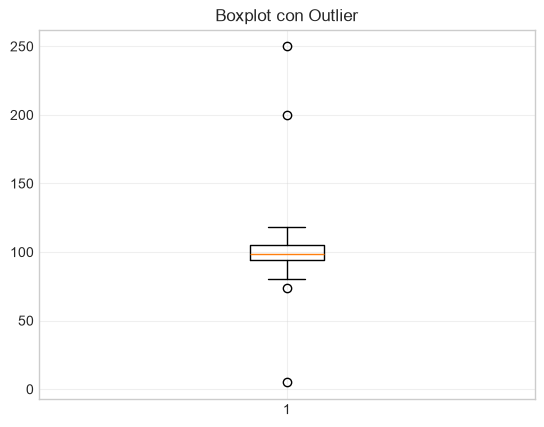

In [35]:
#Detectar por medio de una gráfica 
plt.Figure(figsize=(10,6))
plt.boxplot(df_outliers['valor'])
plt.title('Boxplot con Outlier')
plt.grid(True, alpha=0.3)
plt.show()

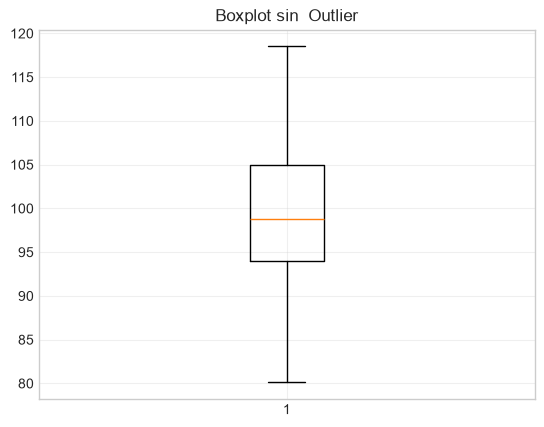

In [36]:
#Detectar por medio de una gráfica 
plt.Figure(figsize=(10,6))
plt.boxplot(df_sin_outliers ['valor'])
plt.title('Boxplot sin  Outlier')
plt.grid(True, alpha=0.3)
plt.show()

In [37]:
df_sin_outliers

,valor
0,104.967142
1,98.617357
2,106.476885
3,115.230299
4,97.658466
...,...
92,92.979469
93,96.723379
94,96.078918
95,85.364851


In [ ]:
#Tus datos cambian, tanto tu desviación estandar y tu media, cambia y mejoran
print(df_sin_outliers.describe())

            valor
count   96.000000
mean    99.187866
std      8.891816
min     80.124311
25%     93.990943
50%     98.730437
75%    105.008525
max    118.522782


----------------------Filtros y selección de filtros avanzados----------------------

In [5]:
data = pd.read_csv("Superstore.csv", encoding = 'latin1')
data.head(10)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
5,6,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
6,7,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.2800,4,0.00,1.9656
7,8,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520,6,0.20,90.7152
8,9,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by S...,18.5040,3,0.20,5.7825
9,10,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9000,5,0.00,34.4700


In [6]:
#Query para filtrar
print(data.query('Quantity > 5 and Quantity <= 9'))

      Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
5          6  CA-2014-115812  2014-06-09  2014-06-14  Standard Class   
7          8  CA-2014-115812  2014-06-09  2014-06-14  Standard Class   
10        11  CA-2014-115812  2014-06-09  2014-06-14  Standard Class   
16        17  CA-2014-105893  2014-11-11  2014-11-18  Standard Class   
21        22  CA-2016-137330  2016-12-09  2016-12-13  Standard Class   
...      ...             ...         ...         ...             ...   
9966    9967  CA-2016-146374  2016-12-05  2016-12-10    Second Class   
9969    9970  CA-2017-153871  2017-12-11  2017-12-17  Standard Class   
9974    9975  US-2016-103674  2016-12-06  2016-12-10  Standard Class   
9977    9978  US-2016-103674  2016-12-06  2016-12-10  Standard Class   
9982    9983  US-2016-157728  2016-09-22  2016-09-28  Standard Class   

     Customer ID    Customer Name      Segment        Country          City  \
5       BH-11710  Brosina Hoffman     Consumer  United S

In [7]:
#Otra forma de filtar con guardado en Excel 
data_filter = data[(data['Quantity'] >= 5 ) & (data['Quantity'] <= 10)]


In [8]:
data_filter

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
5,6,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
7,8,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520,6,0.20,90.7152
9,10,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9000,5,0.00,34.4700
10,11,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9977,9978,US-2016-103674,2016-12-06,2016-12-10,Standard Class,AP-10720,Anne Pryor,Home Office,United States,Los Angeles,...,90032,West,OFF-FA-10003467,Office Supplies,Fasteners,"Alliance Big Bands Rubber Bands, 12/Pack",13.8600,7,0.00,0.0000
9981,9982,CA-2017-163566,2017-08-03,2017-08-06,First Class,TB-21055,Ted Butterfield,Consumer,United States,Fairfield,...,45014,East,OFF-LA-10004484,Office Supplies,Labels,Avery 476,16.5200,5,0.20,5.3690
9982,9983,US-2016-157728,2016-09-22,2016-09-28,Standard Class,RC-19960,Ryan Crowe,Consumer,United States,Grand Rapids,...,49505,Central,OFF-PA-10002195,Office Supplies,Paper,"RSVP Cards & Envelopes, Blank White, 8-1/2"" X ...",35.5600,7,0.00,16.7132
9984,9985,CA-2015-100251,2015-05-17,2015-05-23,Standard Class,DV-13465,Dianna Vittorini,Consumer,United States,Long Beach,...,11561,East,OFF-LA-10003766,Office Supplies,Labels,Self-Adhesive Removable Labels,31.5000,10,0.00,15.1200


In [9]:
#Con pandas y con la extensión Openpyxl y en un formato XLSX
data_filter.to_excel('Resultado_Excel.xlsx', index=False)

In [10]:
#Guardarlo en CSV 
data_filter.to_csv('Resultado_Excel_CSV', index=False, sep=';', encoding='utf-8-sig')

In [11]:
#Filtro con variables 
Valor_maximo = 10
print(data.query('Quantity < @Valor_maximo'))

      Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
0          1  CA-2016-152156  2016-11-08  2016-11-11    Second Class   
1          2  CA-2016-152156  2016-11-08  2016-11-11    Second Class   
2          3  CA-2016-138688  2016-06-12  2016-06-16    Second Class   
3          4  US-2015-108966  2015-10-11  2015-10-18  Standard Class   
4          5  US-2015-108966  2015-10-11  2015-10-18  Standard Class   
...      ...             ...         ...         ...             ...   
9989    9990  CA-2014-110422  2014-01-21  2014-01-23    Second Class   
9990    9991  CA-2017-121258  2017-02-26  2017-03-03  Standard Class   
9991    9992  CA-2017-121258  2017-02-26  2017-03-03  Standard Class   
9992    9993  CA-2017-121258  2017-02-26  2017-03-03  Standard Class   
9993    9994  CA-2017-119914  2017-05-04  2017-05-09    Second Class   

     Customer ID     Customer Name    Segment        Country             City  \
0       CG-12520       Claire Gute   Consumer  United 

In [12]:
# Usando eval() para crear columnas calculadas 
print(data.eval('Ganancias = Sales * Quantity'))

      Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
0          1  CA-2016-152156  2016-11-08  2016-11-11    Second Class   
1          2  CA-2016-152156  2016-11-08  2016-11-11    Second Class   
2          3  CA-2016-138688  2016-06-12  2016-06-16    Second Class   
3          4  US-2015-108966  2015-10-11  2015-10-18  Standard Class   
4          5  US-2015-108966  2015-10-11  2015-10-18  Standard Class   
...      ...             ...         ...         ...             ...   
9989    9990  CA-2014-110422  2014-01-21  2014-01-23    Second Class   
9990    9991  CA-2017-121258  2017-02-26  2017-03-03  Standard Class   
9991    9992  CA-2017-121258  2017-02-26  2017-03-03  Standard Class   
9992    9993  CA-2017-121258  2017-02-26  2017-03-03  Standard Class   
9993    9994  CA-2017-119914  2017-05-04  2017-05-09    Second Class   

     Customer ID     Customer Name    Segment        Country             City  \
0       CG-12520       Claire Gute   Consumer  United 

In [13]:
#Ver en la tabla, y así poder exportar con las columnas calculadas
data['Ganacias'] = data['Sales'] * data['Quantity']


In [14]:
print(data.columns)

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Ganacias'],
      dtype='str')


In [15]:
#Otra forma de Remplazar la columna principal 

data.eval('Ganacias2 = Sales * Quantity', inplace=True)

C:\Users\SAUL\AppData\Local\Temp\ipykernel_2144\2266502277.py:3: Pandas4Warning: The inplace keyword in DataFrame.eval is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.eval('Ganacias2 = Sales * Quantity', inplace=True)


------------Selección Avanzada con .loc, iloc, .at y .ait ----------------

In [16]:
#Selección con .loc (basadas en etiquetas) del 1:100 son filas y ['Segement','Country'] son columnas
print(data.loc[1:100,['Segment','Country']])

         Segment        Country
1       Consumer  United States
2      Corporate  United States
3       Consumer  United States
4       Consumer  United States
5       Consumer  United States
..           ...            ...
96   Home Office  United States
97      Consumer  United States
98     Corporate  United States
99   Home Office  United States
100  Home Office  United States

[100 rows x 2 columns]


In [17]:
# Selección con.ILOC (con base en posiciciones) cuando es en posiciones es de Python que empieza con 0 
# Lo mismo filas y columnas(columnas es 0 y 6 nada más)
print(data.iloc[1:4,[0,6]])

   Row ID    Customer Name
1       2      Claire Gute
2       3  Darrin Van Huff
3       4   Sean O'Donnell


In [20]:
#Seleccióna de la Columna X mayores a X pero muestrame otras columnas 

print(data.loc[data['Profit'] > 10.000, ['Region', 'Product ID', 'Category', 'Sub-Category']])

     Region       Product ID         Category Sub-Category
0     South  FUR-BO-10001798        Furniture    Bookcases
1     South  FUR-CH-10000454        Furniture       Chairs
5      West  FUR-FU-10001487        Furniture  Furnishings
7      West  TEC-PH-10002275       Technology       Phones
9      West  OFF-AP-10002892  Office Supplies   Appliances
...     ...              ...              ...          ...
9988  South  TEC-PH-10004006       Technology       Phones
9990   West  FUR-FU-10000747        Furniture  Furnishings
9991   West  TEC-PH-10003645       Technology       Phones
9992   West  OFF-PA-10004041  Office Supplies        Paper
9993   West  OFF-AP-10002684  Office Supplies   Appliances

[4607 rows x 4 columns]


In [ ]:
#Encontrar X valor 
print(data.at[1600,'Region']) # Por etiqueta 

Central


In [ ]:
print(data.iat[1800,6]) # Por posición

Jill Fjeld
